# Tugas Besar 2 IF3170 Inteligensi Artifisial

*Klasifikasi pembatalan pemesanan penginapan.*

## Group 08 — Teazzi

- Jason Edward Salim (13524034)
- Stefani Angeline Oroh (13524064)
- Bryan Pratama Putra Hendra (13524067)
- Angelina Andra Alanna (13524079)
- Michael James Liman (13524106)

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

Pembatalan reservasi dapat membuat kamar yang sudah disiapkan kembali kosong. Hotel dapat memakai prediksi untuk merencanakan ketersediaan kamar dan menentukan reservasi yang perlu ditindaklanjuti.

## Aim

Prediksi `is_canceled` untuk setiap reservasi. Label `1` berarti batal dan label `0` berarti tidak batal.

## Metric

Macro F1 merata-ratakan F1 kelas batal dan kelas tidak batal. Kedua kelas mendapat bobot yang sama meski jumlah booking-nya berbeda.

## Dataset

`train.csv` berisi reservasi berlabel. `test.csv` berisi reservasi tanpa label yang akan diprediksi untuk Kaggle. Setiap baris memiliki satu `id` reservasi.

## Approach

Pisahkan data latih dan validasi, siapkan fitur per model, lalu bandingkan lima algoritma dari nol dengan baseline scikit-learn. Gunakan konfigurasi KNN yang dipilih untuk melatih ulang model pada seluruh data berlabel dan membuat submission.

---

# Initialization <a name="2"></a>

---

## Environment Setup

Buka notebook dari root repo atau folder `src`. Dependensi tercantum di `requirements.txt` pada root repo.

## Import Libraries

In [1]:
import sys
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

src_dir = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
sys.path.insert(0, str(src_dir))

from config import Settings, seed_everything
from eda import types, histogram, boxplot, iqr_outliers, target_rate, correlation
from logistic_submission import run_three_solver_submissions
from models import KNN, LogisticRegression, SVM, DTL, BayesNetwork
from models.base import BaseModel
from models.bayes_graph import plot_bayes_graph
from models.dtl import plot_tree
from preprocessing import load_data, split, drop_duplicates, Preprocessor, Pipeline
from validation import (
    fit, fit_predict, model_input, macro_f1, holdout, kfold, compare, tune, best,
    importance, confusion, report, misclassified, submit, with_threshold,
)

Matplotlib is building the font cache; this may take a moment.


## Settings

Path data dan output, nama target, serta konfigurasi validasi berasal dari `src/config.py`.

In [2]:
Settings.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

In [3]:
seed_everything()

## Load Dataset

`load_data()` membaca `id` sebagai teks agar format identitas reservasi tetap utuh.

In [4]:
train, test = load_data()
pd.DataFrame([train.shape, test.shape], index=["train", "test"], columns=["Baris", "Kolom"])

,Baris,Kolom
train,27373,19
test,6844,18


---

# Data Understanding (Optional) <a name="3"></a>

---

## Describe Data

| Kelompok | Kolom dan makna |
| --- | --- |
| Identitas dan target | `id` adalah ID reservasi, `is_canceled` adalah status pembatalan. |
| Tamu dan permintaan | `num_adults`, `num_children`, `needs_parking`, dan `special_requests` mencatat jumlah tamu, kebutuhan parkir, dan permintaan khusus. |
| Jadwal | `arrival_year`, `arrival_month`, dan `arrival_day` membentuk tanggal kedatangan. `days_before_arrival` mengukur jeda pemesanan. `weekday_nights` dan `weekend_nights` menghitung malam menginap. |
| Paket dan harga | `meal_package`, `room_category`, `booking_channel`, dan `nightly_rate_idr` mencatat paket makan, kategori kamar, kanal pemesanan, dan tarif per malam. |
| Riwayat | `is_returning_guest`, `prior_cancellations`, dan `prior_completed_bookings` merangkum status tamu lama dan riwayat reservasinya. |

In [5]:
train.head()

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


In [6]:
types(train)

,dtype,kind,unique
id,str,categorical,27373
num_adults,float64,numeric,5
num_children,float64,numeric,6
weekend_nights,int64,numeric,8
weekday_nights,int64,numeric,18
meal_package,str,categorical,4
needs_parking,float64,numeric,2
room_category,str,categorical,7
days_before_arrival,float64,numeric,407
arrival_year,int64,numeric,2


## Explore Data

Sekitar 32,8% reservasi pada data berlabel dibatalkan. Di antara fitur numerik, `days_before_arrival` memiliki korelasi Pearson terbesar dengan target (0,44). Korelasi ini menggambarkan asosiasi pada data dan belum mengukur pengaruh suatu fitur pada prediksi.

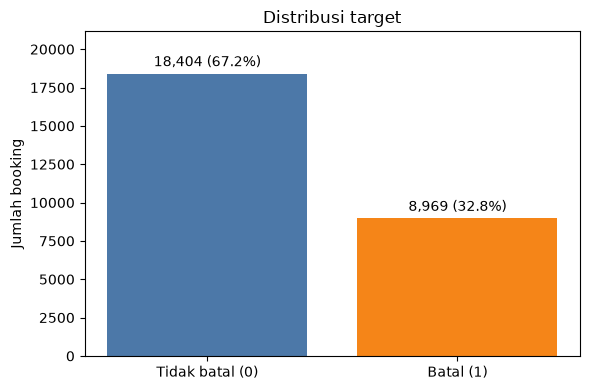

In [7]:
target_counts = train[Settings.TARGET].value_counts().reindex([0, 1], fill_value=0)
target_labels = ["Tidak batal (0)", "Batal (1)"]
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(target_labels, target_counts.values, color=["#4C78A8", "#F58518"])
ax.set(title="Distribusi target", ylabel="Jumlah booking")
ax.bar_label(
    bars,
    labels=[f"{count:,} ({count / len(train):.1%})" for count in target_counts.values],
    padding=3,
)
ax.set_ylim(0, target_counts.max() * 1.15)
plt.tight_layout()
plt.show()

In [8]:
num_col = train.select_dtypes("number").columns.drop(Settings.TARGET)
cat_col = train.columns.difference(num_col).drop([Settings.ID, Settings.TARGET])

display(train[num_col].describe().T)
display(train[cat_col].describe().T)

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


,count,unique,top,freq
booking_channel,27373,5,Online Travel Agent,17511
meal_package,25613,4,Breakfast,19654
room_category,26371,7,Type B,20447


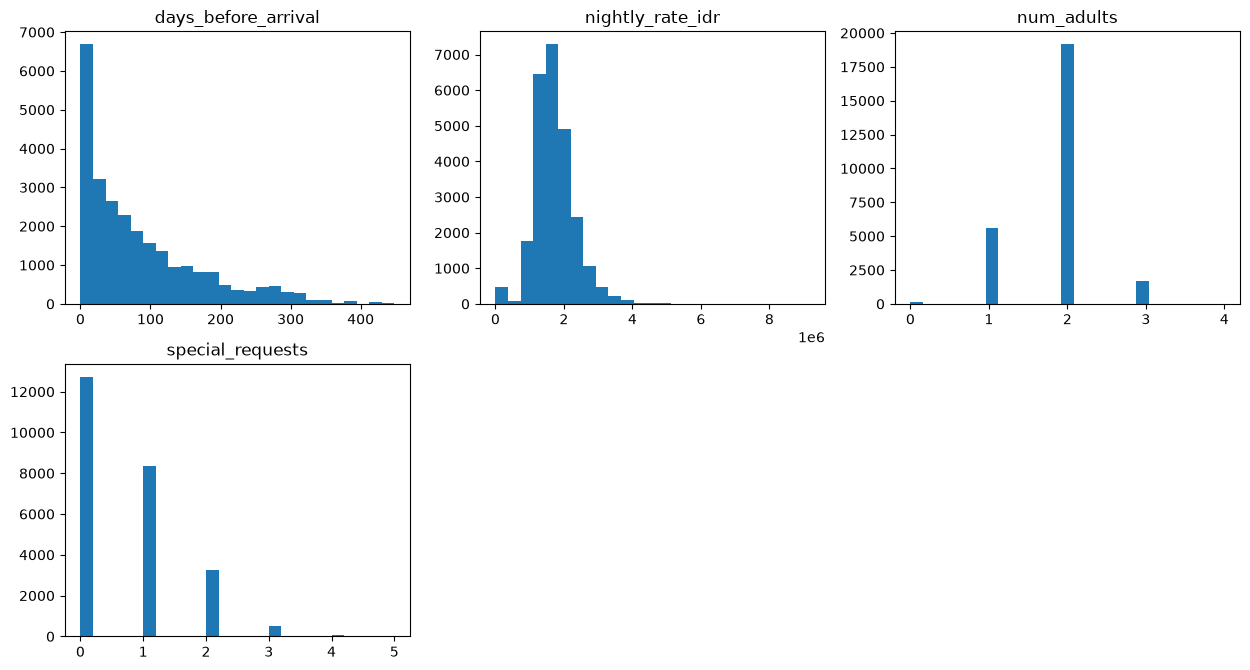

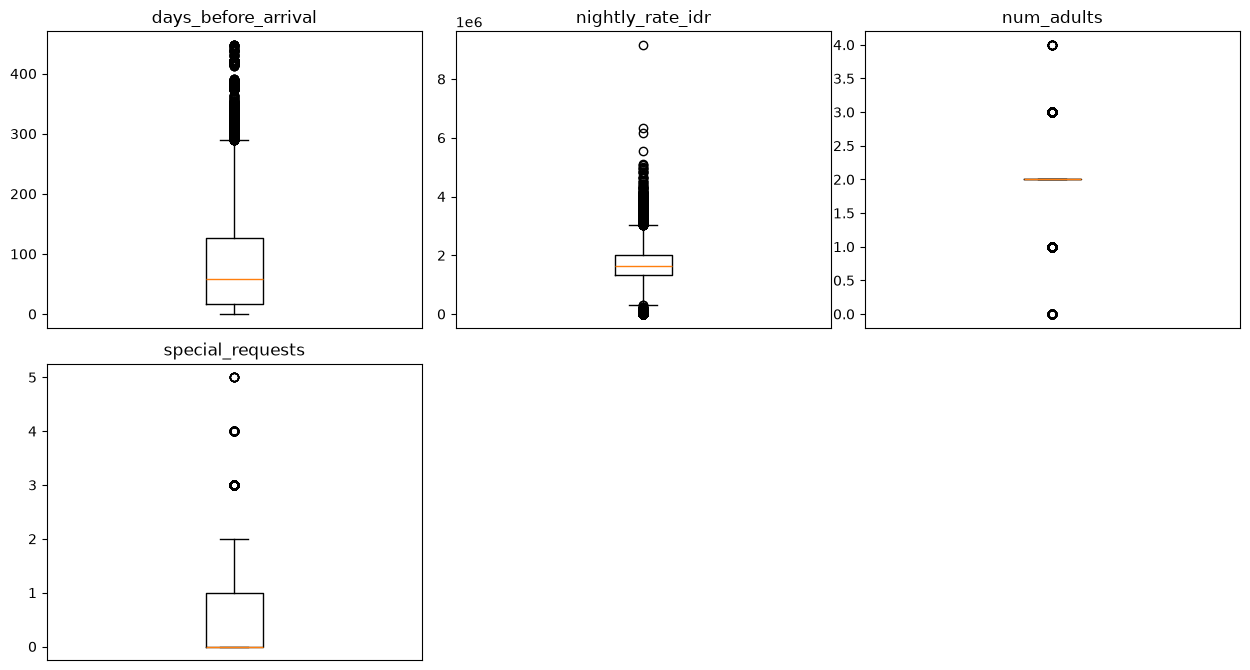

In [9]:
focus_features = ["days_before_arrival", "nightly_rate_idr", "num_adults", "special_requests"]
histogram(train, focus_features, bins=25)
boxplot(train, focus_features)

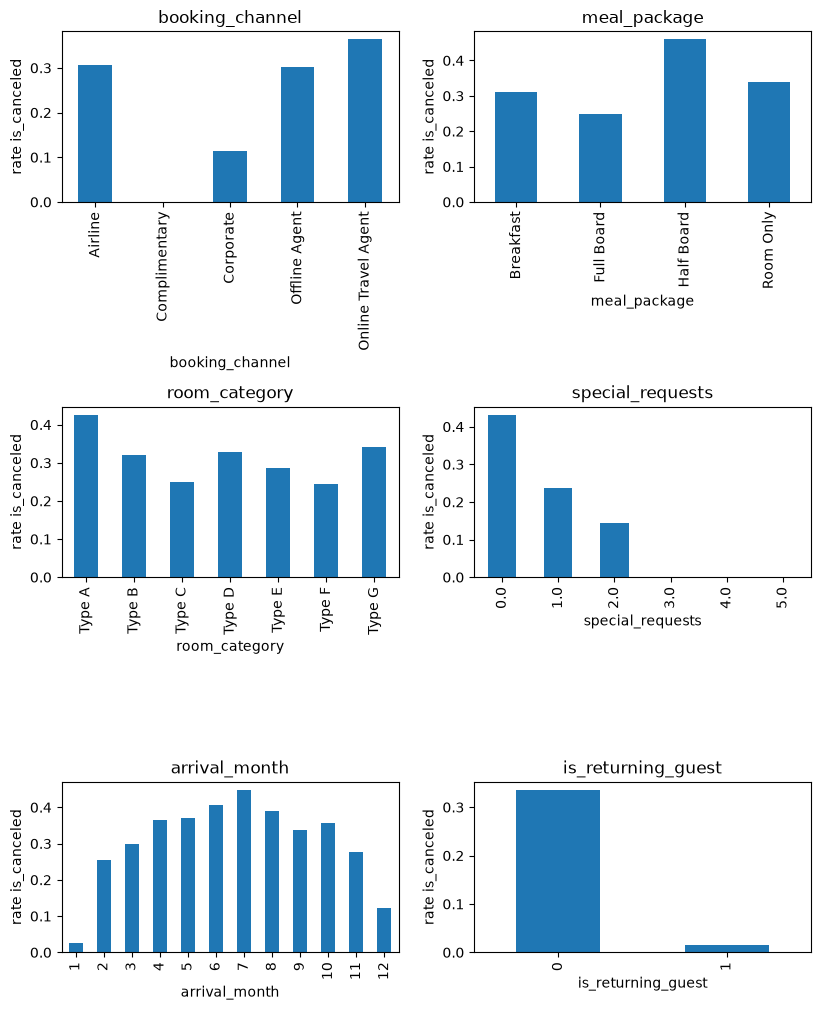

In [10]:
target_rate(
    train,
    ["booking_channel", "meal_package", "room_category", "special_requests", "arrival_month", "is_returning_guest"],
)

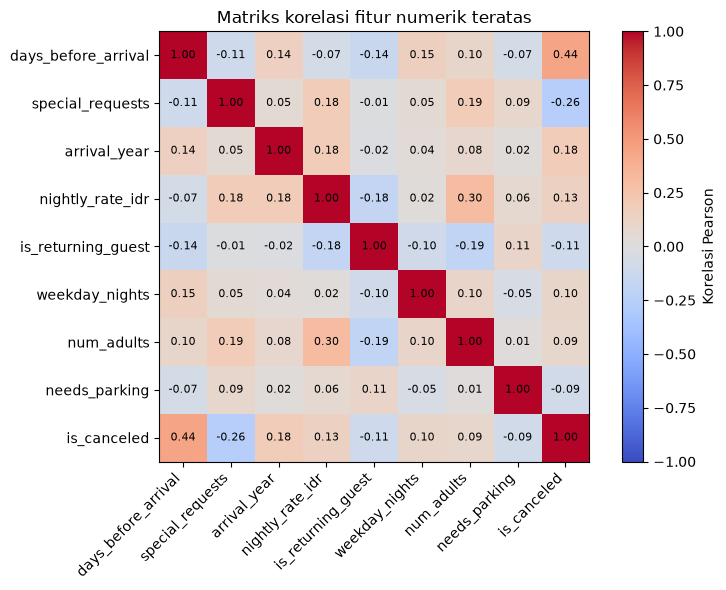

In [11]:
target_corr = correlation(train)
selected_features = target_corr.head(8).index.tolist()
corr_matrix = train[selected_features + [Settings.TARGET]].corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_matrix.index)), corr_matrix.index)
ax.set_title("Matriks korelasi fitur numerik teratas")
for row in range(len(corr_matrix.index)):
    for column in range(len(corr_matrix.columns)):
        value = corr_matrix.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Korelasi Pearson")
plt.tight_layout()
plt.show()

## Verify Data Quality

Periksa missing value dan duplikat pada data berlabel. Duplikat dihitung dari kolom fitur, karena setiap reservasi memiliki ID tersendiri.

,Missing (%)
num_children,11.09
special_requests,9.13
nightly_rate_idr,7.45
meal_package,6.43
days_before_arrival,4.10
needs_parking,3.95
room_category,3.66
num_adults,2.96


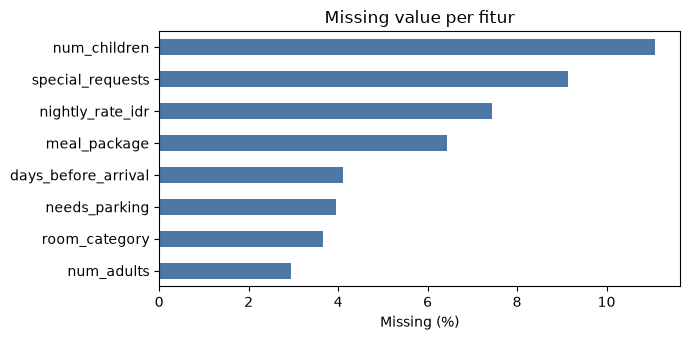

In [12]:
feature_data = train.drop(columns=[Settings.ID, Settings.TARGET])
missing_pct = feature_data.isna().mean().mul(100)
missing_pct = missing_pct[missing_pct.gt(0)].sort_values()
display(missing_pct.sort_values(ascending=False).round(2).rename("Missing (%)").to_frame())

if not missing_pct.empty:
    ax = missing_pct.plot.barh(figsize=(7, 3.5), color="#4C78A8")
    ax.set(title="Missing value per fitur", xlabel="Missing (%)", ylabel="")
    plt.tight_layout()
    plt.show()

In [13]:
pd.Series(
    {"ID duplikat": train[Settings.ID].duplicated().sum(), "Baris fitur duplikat": feature_data.duplicated().sum()},
    name="Jumlah",
)

ID duplikat              0
Baris fitur duplikat    66
Name: Jumlah, dtype: int64

---

# Training and Validation Split <a name="4"></a>

---

Stratified holdout membagi `train.csv` menjadi sekitar 80% train dan 20% validation. Pembagian dilakukan sebelum pembersihan dan sebelum statistik preprocessing dihitung.

In [14]:
X_fit_raw, X_val_raw, y_fit, y_val = split(train)
pd.Series({"train": len(X_fit_raw), "validation": len(X_val_raw)}, name="Baris")

train         21898
validation     5475
Name: Baris, dtype: int64

---

# Data Preparation <a name="5"></a>

---

## Select Data

**Insight.** `split()` memisahkan `is_canceled` sebagai target dan mengeluarkan `id` dari fitur. ID tetap tersedia di data asli untuk menelusuri reservasi dan membuat submission.

## Clean Data

### Missing Values

**Insight.** `num_children` punya tingkat missing tertinggi pada data berlabel, sekitar 11,1%. Preprocessor mengisi nilai numerik dengan median dan kategori dengan modus dari split latih. Harga dan jeda pemesanan memakai median kelompok sebelum imputasi umum. LR dan SVM juga memakai penanda missing untuk `special_requests`.

### Duplicates

**Insight.** Buang salinan fitur dari split latih untuk mengurangi bobot contoh berulang. Validation tetap mempertahankan baris hasil split.

In [15]:
X_train_raw, y_train = drop_duplicates(X_fit_raw, y_fit)
pd.Series({"Baris latih": len(X_train_raw), "Duplikat dibuang": len(X_fit_raw) - len(X_train_raw)})

Baris latih         21857
Duplikat dibuang       41
dtype: int64

### Outliers

**Insight.** Capping berbasis IQR diterapkan pada `days_before_arrival` dan `nightly_rate_idr` untuk konfigurasi yang memakai `CAP`. Nilai ekstrem dibatasi tanpa membuang reservasinya. Pipeline pohon mempertahankan nilai awal.

In [16]:
iqr_outliers(X_train_raw, ["days_before_arrival", "nightly_rate_idr"])

days_before_arrival    726
nightly_rate_idr       904
Name: outlier, dtype: int64

### Data Errors

**Insight.** Periksa kelengkapan ID, validitas tanggal kedatangan, nilai numerik negatif, dan domain target. Pada data berlabel yang dipakai, pemeriksaan ini tidak menemukan nilai yang perlu dikoreksi.

In [17]:
arrival = pd.to_datetime(
    train.loc[X_train_raw.index, ["arrival_year", "arrival_month", "arrival_day"]]
    .rename(columns={"arrival_year": "year", "arrival_month": "month", "arrival_day": "day"}),
    errors="coerce",
)
pd.Series(
    {
        "ID kosong": train.loc[X_train_raw.index, Settings.ID].isna().sum(),
        "Tanggal tidak valid": arrival.isna().sum(),
        "Nilai numerik negatif": X_train_raw.select_dtypes("number").lt(0).sum().sum(),
        "Target di luar 0/1": (~y_train.isin([0, 1])).sum(),
    },
    name="Jumlah",
)

ID kosong                0
Tanggal tidak valid      0
Nilai numerik negatif    0
Target di luar 0/1       0
Name: Jumlah, dtype: int64

## Construct Data

### Attribute Construction

**Insight.** `Preprocessor` membentuk fitur seperti `total_nights`, `total_guests`, `price_per_guest`, dan fitur tanggal dari kolom yang sudah ada. `date_rate` merangkum tingkat pembatalan per tanggal kedatangan. SVM juga memakai statistik booking serupa dan target encoding. Untuk baris train, fitur berbasis label dihitung secara *out-of-fold*.

### Feature Scaling

**Insight.** KNN memakai robust scaling agar perbedaan skala fitur tidak mendominasi jarak dan nilai ekstrem lebih sedikit memengaruhi skala. Pipeline lain memakai standardisasi sesuai konfigurasi model. DTL tidak memakai scaling.

### Encoding

**Insight.** Paket makan dan kategori kamar memakai ordinal encoding pada pipeline yang memilih urutan tersebut. Kategori lain memakai one-hot encoding. LR memakai one-hot untuk bin kuantil pada fitur numerik tertentu.

### Dimensionality Reduction

**Insight.** Baseline KNN memilih 12 fitur dari ranking DTL. Eksperimen SVM linear memilih 10 fitur berdasarkan nilai absolut bobot. Model utama SVM memakai kernel RBF dan tidak memakai seleksi linear ini. PCA tidak digunakan pada model utama.

## Class Balance

**Insight.** Macro F1 memberi bobot yang sama pada kedua kelas. Konfigurasi utama memakai distribusi kelas asli dengan `METHOD = None`.

In [18]:
METHOD = None
y_train.value_counts(normalize=True).sort_index().mul(100).round(2).rename("Proporsi (%)")

is_canceled
0    67.25
1    32.75
Name: Proporsi (%), dtype: float64

## Format Data

**Insight.** Setiap pipeline menghasilkan matriks fitur numerik dengan urutan kolom yang sama untuk train dan validation. Pemisahan target dan urutan kolom dipertahankan sampai model menerima input.

---

# Preparation Pipeline <a name="6"></a>

---

Preprocessor mempelajari statistik dari split latih dan menerapkannya ke validation. `X_trains` dan `X_vals` memberi setiap model matriks yang sesuai dengan konfigurasinya.

| Pipeline | Penyesuaian utama |
| --- | --- |
| KNN | Robust scaling, fitur tanggal dan harga, smoothing `date_rate=5` |
| DTL | Encoding kategori, tanpa scaling dan capping |
| Logistic Regression | Binning kuantil untuk fitur terpilih dan standardisasi |
| SVM | Fitur kemiripan booking, penanda missing dan target encoding |
| Naive Bayes | Preprocessing default, lalu diskretisasi fitur di model |

In [19]:
CAP = ["days_before_arrival", "nightly_rate_idr"]
ORDINAL = {
    "meal_package": ["Room Only", "Breakfast", "Half Board", "Full Board"],
    "room_category": [f"Type {c}" for c in "ABCDEFG"],
}
NEW_FEATURES = ["arrival_weekday", "booking_month", "booking_weekday", "price_per_guest", "nightly_rate_idr_ratio", "days_before_arrival_ratio"]
TARGET_ENCODE = [
    ("arrival_year", "arrival_month", "lead_band"), ("nights", "booking_channel", "lead_band"), ("date", "lead_band"),
    ("week", "lead_band"), ("date", "booking_channel"), ("room_category", "lead_band"), ("special_requests", "lead_band"),
    ("booking_channel", "room_category"), ("arrival_year", "arrival_month", "booking_channel"), ("date", "nights"),
    ("meal_package", "lead_band"), ("num_adults", "booking_channel", "lead_band"), ("lead20", "special_requests", "booking_channel"),
    ("lead20", "arrival_year", "arrival_month"), ("lead_band", "special_requests", "booking_channel", "arrival_year"),
    ("lead20", "room_category", "special_requests"), ("price10", "lead_band"), ("price10", "room_category", "arrival_year"),
    ("price10", "special_requests", "booking_channel"), ("price10", "arrival_year", "arrival_month"),
]
BINNED = ["days_before_arrival", "nightly_rate_idr", "arrival_month", "date_rate", "special_requests", "total_nights",
          "arrival_weekday", "booking_month", "price_per_guest", "num_adults"]

SVM_PREP_OPTIONS = {
    "cap": CAP,
    "ordinal": ORDINAL,
    "flag_missing": ["special_requests"],
    "near_dup": True,
    "near_tols": [(0, 10, 0.03), (0, 10, 0.10)],
    "target_encode": TARGET_ENCODE,
    "te_smoothing": 5,
}

preps = {
    "default": Preprocessor(
        zero_as_missing=[],
        num_strategy="median",
        cap=CAP,
        ordinal=ORDINAL,
        scaler="standard",
        drop=NEW_FEATURES,
    ),
    "svm": Preprocessor(**SVM_PREP_OPTIONS),
    "tree": Preprocessor(ordinal=ORDINAL, scaler=None, drop=NEW_FEATURES),
    "knn": Preprocessor(cap=CAP, ordinal=ORDINAL, scaler="robust", smoothing=5),
    "lr": Preprocessor(cap=CAP, flag_missing=["special_requests"], binned=BINNED, n_bins=20),
}
uses = {"svm": "svm", "bn": "default", "bn_kdb": "default", "dtl": "tree", "knn": "knn", "lr": "lr",
        "sk_svm": "svm", "sk_nb": "default", "sk_dtl": "tree", "sk_knn": "knn", "sk_lr": "lr"}

prepared = {
    name: (prep.fit_transform(X_train_raw, y_train), prep.transform(X_val_raw))
    for name, prep in preps.items()
}
X_trains = {model: prepared[prep][0] for model, prep in uses.items()}
X_vals = {model: prepared[prep][1] for model, prep in uses.items()}
X_train, X_val = prepared["default"]

pd.DataFrame(
    {name: {"Train": len(train_X), "Validation": len(val_X), "Fitur": train_X.shape[1]}
     for name, (train_X, val_X) in prepared.items()}
).T

,Train,Validation,Fitur
default,21857,5475,30
svm,21857,5475,61
tree,21857,5475,30
knn,21857,5475,36
lr,21857,5475,171


---

# Modeling and Validation <a name="7"></a>

---

Model dari nol berada di `src/models/`. Setiap konfigurasi dasar di bawah dilatih pada split train dan dinilai dengan macro F1 pada holdout. Nama model dipakai untuk mengambil matriks preprocessing yang sesuai.

In [20]:
models = {}

## K-Nearest Neighbors

Model menghitung jarak Manhattan dan memberi bobot suara lebih besar pada tetangga yang lebih dekat. Bobot fitur mengatur kontribusi setiap kolom pada jarak.

In [21]:
knn_config = {
    "k": 91,
    "metric": "manhattan",
    "vote_weights": "inverse_square",
    "feature_weights": {
        "meal_package": 0.2,
        "room_category": 0.25,
        "date_rate": 0.5,
        "month_sin": 0,
        "month_cos": 0,
        "doy_sin": 0,
        "doy_cos": 0,
    },
    "threshold": 0.45,
}
models["knn"] = KNN(**knn_config)

## Decision Tree Learning

CART memilih pemisahan biner menggunakan Gini impurity. Cost-complexity pruning mengendalikan ukuran pohon.

In [22]:
models["dtl"] = DTL(criterion="gini", ccp_alpha=3e-4)

## Logistic Regression

Model menggunakan sigmoid untuk memprediksi peluang pembatalan. Implementasinya mendukung L1, L2, dan Elastic Net. Konfigurasi dasar memakai SGD tanpa regularisasi.

In [23]:
models["lr"] = LogisticRegression(lr=0.5, n_iter=3000)

## Support Vector Machine

Implementasi SMO mendukung kernel linear, polinomial, dan Gaussian. Konfigurasi utama menggunakan kernel Gaussian (RBF).

In [24]:
models["svm"] = SVM(kernel="rbf", C=2, gamma=0.025)

## Naive Bayes

Model mendiskretisasi fitur numerik sebelum menghitung distribusi fitur per kelas. KDB menjadi eksperimen tambahan yang mengizinkan dependensi antarfitur.

In [25]:
models["bn"] = BayesNetwork()
models["bn_kdb"] = BayesNetwork(n_bins=5, k=10)

## Model Evaluation

In [26]:
fitted_models = {name: fit(model, X_trains[name], y_train, METHOD) for name, model in models.items()}
scratch_holdout = pd.Series(
    {name: macro_f1(y_val, model.predict(model_input(model, X_vals[name])))
     for name, model in fitted_models.items()},
    name="holdout",
).to_frame()
scratch_cv = kfold(models, X_trains, y_train, METHOD)
compare(scratch_holdout, scratch_cv).round(4)

,holdout,kfold_mean,kfold_std
svm,0.8688,0.8645,0.0037
knn,0.8423,0.8382,0.0051
dtl,0.8277,0.8223,0.0070
bn_kdb,0.8112,0.8124,0.0029
bn,0.7050,0.7093,0.0061
lr,0.7597,0.6861,0.0397


## Improvements (Optional)

### Hyperparameter Tuning

Grid KNN membandingkan jumlah tetangga dan threshold. Grid model lain memakai parameter yang tercantum di cell berikutnya. CV di sini memakai matriks dari Preparation Pipeline, sehingga preprocessor tidak dilatih ulang per fold CV. Gunakan skor holdout sebagai acuan utama untuk menilai generalisasi.

,k,threshold,kfold_mean,kfold_std
0,71,0.46,0.8388,0.0034
1,71,0.45,0.8387,0.0033
2,71,0.44,0.8384,0.0026
3,91,0.45,0.8382,0.0051
4,91,0.44,0.8382,0.0031
5,91,0.42,0.8380,0.0028
6,71,0.42,0.8378,0.0032
7,111,0.42,0.8375,0.0030
8,111,0.44,0.8373,0.0038
9,71,0.48,0.8372,0.0050


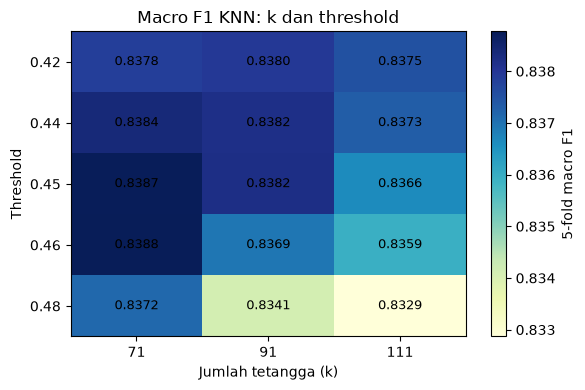

In [27]:
KNN_THRESHOLDS = [0.42, 0.44, 0.45, 0.46, 0.48]
grids = {
    "knn": {"k": [71, 91, 111], "threshold": KNN_THRESHOLDS},
    "lr": {"lr": [0.1, 0.5], "n_iter": [1000, 3000]},
    "svm": {"kernel": ["rbf"], "C": [1, 2], "gamma": [0.025, 0.035]},
    "dtl": {"ccp_alpha": [1e-4, 2e-4, 3e-4, 5e-4]},
    "bn": {"n_bins": [3, 5, 10]},
    "bn_kdb": {"k": [6, 8, 10]},
}

grid_tables = {name: tune(models[name], grid, X_trains[name], y_train, METHOD) for name, grid in grids.items()}
tuned_models = {name: best(models[name], table) for name, table in grid_tables.items()}

knn_grid = grid_tables["knn"]
display(knn_grid[["k", "threshold", "kfold_mean", "kfold_std"]].round(4))
knn_matrix = knn_grid.pivot(index="threshold", columns="k", values="kfold_mean").sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(knn_matrix, cmap="YlGnBu", aspect="auto")
ax.set(xticks=range(len(knn_matrix.columns)), xticklabels=knn_matrix.columns,
       yticks=range(len(knn_matrix.index)), yticklabels=[f"{value:.2f}" for value in knn_matrix.index],
       xlabel="Jumlah tetangga (k)", ylabel="Threshold", title="Macro F1 KNN: k dan threshold")
for row in range(len(knn_matrix.index)):
    for column in range(len(knn_matrix.columns)):
        ax.text(column, row, f"{knn_matrix.iloc[row, column]:.4f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="5-fold macro F1")
plt.tight_layout()
plt.show()

In [28]:
ranking = compare(
    holdout(tuned_models, X_trains, y_train, X_vals, y_val, METHOD),
    kfold(tuned_models, X_trains, y_train, METHOD),
)
ranking

,holdout,kfold_mean,kfold_std
svm,0.867143,0.864614,0.003911
knn,0.840963,0.838772,0.003418
dtl,0.827676,0.822254,0.007047
bn_kdb,0.811249,0.812400,0.002917
lr,0.756682,0.727365,0.015394
bn,0.709192,0.713424,0.006335


### SVM Feature Selection

SVM diselesaikan dalam bentuk dual dengan SMO, sehingga untuk kernel linear w = Σ αᵢyᵢxᵢ. Fitur diranking berdasarkan nilai absolut bobot SVM linear yang dilatih pada seluruh fitur, lalu `select` fitur teratas dipakai untuk melatih ulang SVM. Model SVM utama memakai kernel RBF, yang tidak memiliki w eksplisit.

In [29]:
svm_fitted = fit(Pipeline(SVM(kernel="linear", C=0.1), select=10), X_train, y_train)
pd.Series(X_train.columns[svm_fitted.keep], name="svm selected features")

0                          needs_parking
1                       special_requests
2          booking_channel_Offline Agent
3                    days_before_arrival
4    booking_channel_Online Travel Agent
5                     is_returning_guest
6                              date_rate
7                booking_channel_Airline
8                           lead_x_price
9          booking_channel_Complimentary
Name: svm selected features, dtype: str

### Bonus DTL

DTL yang dipakai adalah **CART**: setiap simpul memecah data menjadi dua dengan *gini impurity*, yaitu `x <= t` untuk fitur numerik dan `x ∈ S` untuk fitur kategorikal. Untuk dua kelas, himpunan kategori `S` terbaik dicari dengan mengurutkan kategori menurut proporsi kelas 1, lalu memperlakukannya seperti fitur numerik (Breiman dkk., 1984). Nilai kosong tidak ikut menentukan ambang. *Gain* fitur dikalikan proporsi baris yang nilainya diketahui (Quinlan, 1993), dan baris dengan nilai kosong mengikuti cabang yang menerima lebih banyak sampel latih. Pada prediksi, nilai kosong dan kategori yang tidak pernah muncul di simpul tersebut mengikuti arah yang sama.

#### Minimal cost-complexity pruning

Pohon penuh tumbuh sampai setiap daun murni sehingga *overfitting*. *Minimal cost-complexity pruning* memangkas pohon penuh menjadi subpohon $T$ yang meminimalkan $R_\alpha(T) = R(T) + \alpha |\tilde T|$, dengan $R(T)$ jumlah *impurity* daun yang dibobot proporsi sampel dan $|\tilde T|$ jumlah daun. Pemangkasan dilakukan dari bawah ke atas: simpul $t$ dijadikan daun jika $R(t) + \alpha$ tidak lebih besar daripada biaya subpohon terbaiknya. $\alpha$ dipilih dengan 5-fold CV (parameter `ccp_alpha`, sama dengan scikit-learn).

> Referensi: L. Breiman, J. Friedman, R. Olshen, dan C. Stone, *Classification and Regression Trees*, Wadsworth, 1984, bab 3. [scikit-learn: Minimal Cost-Complexity Pruning](https://scikit-learn.org/stable/modules/tree.html#minimal-cost-complexity-pruning)

> Referensi: J. R. Quinlan, *C4.5: Programs for Machine Learning*, Morgan Kaufmann, 1993.

In [30]:
dtl_variants = {
    "full tree": DTL(criterion="gini"),
    "max_depth=10": DTL(criterion="gini", max_depth=10),
    "ccp_alpha=1e-4": DTL(criterion="gini", ccp_alpha=1e-4),
    "ccp_alpha=3e-4": DTL(criterion="gini", ccp_alpha=3e-4),
    "ccp_alpha=1e-3": DTL(criterion="gini", ccp_alpha=1e-3),
}
dtl_table = compare(holdout(dtl_variants, X_trains["dtl"], y_train, X_vals["dtl"], y_val, METHOD),
                    kfold(dtl_variants, X_trains["dtl"], y_train, METHOD))
dtl_table["leaves"] = [fit(dtl_variants[name], X_trains["dtl"], y_train, METHOD).n_leaves() for name in dtl_table.index]
dtl_table

,holdout,kfold_mean,kfold_std,leaves
ccp_alpha=3e-4,0.827676,0.822254,0.007047,122
max_depth=10,0.829249,0.820529,0.005604,394
ccp_alpha=1e-3,0.809317,0.809950,0.003903,29
ccp_alpha=1e-4,0.825160,0.809581,0.001992,697
full tree,0.804180,0.798159,0.002447,2526


#### Nilai kosong dan kategorikal tanpa preprocessing

DTL juga dapat dilatih langsung pada data mentah: tiga kolom kategorikal (`meal_package`, `room_category`, `booking_channel`) tetap berupa teks dan delapan kolom tetap berisi nilai kosong.

In [31]:
raw_train, raw_val = X_train_raw, X_val_raw
print(f"{raw_train.isna().sum().sum()} sel kosong, kolom teks: {list(raw_train.select_dtypes(exclude='number').columns)}")
raw_models = {"dtl (data mentah)": models["dtl"], "dtl (preprocessing tree)": models["dtl"]}
compare(holdout(raw_models, {"dtl (data mentah)": raw_train, "dtl (preprocessing tree)": X_trains["dtl"]}, y_train,
                {"dtl (data mentah)": raw_val, "dtl (preprocessing tree)": X_vals["dtl"]}, y_val, METHOD),
        kfold(raw_models, {"dtl (data mentah)": raw_train, "dtl (preprocessing tree)": X_trains["dtl"]}, y_train, METHOD))

10677 sel kosong, kolom teks: ['meal_package', 'room_category', 'booking_channel']


,holdout,kfold_mean,kfold_std
dtl (preprocessing tree),0.827676,0.822254,0.007047
dtl (data mentah),0.814496,0.809382,0.002993


#### Visualisasi Pohon

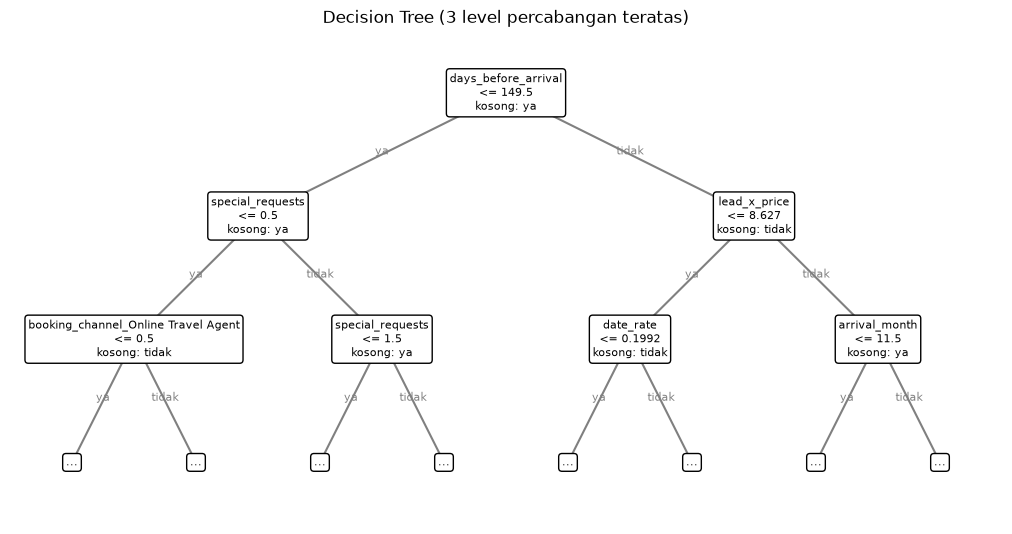

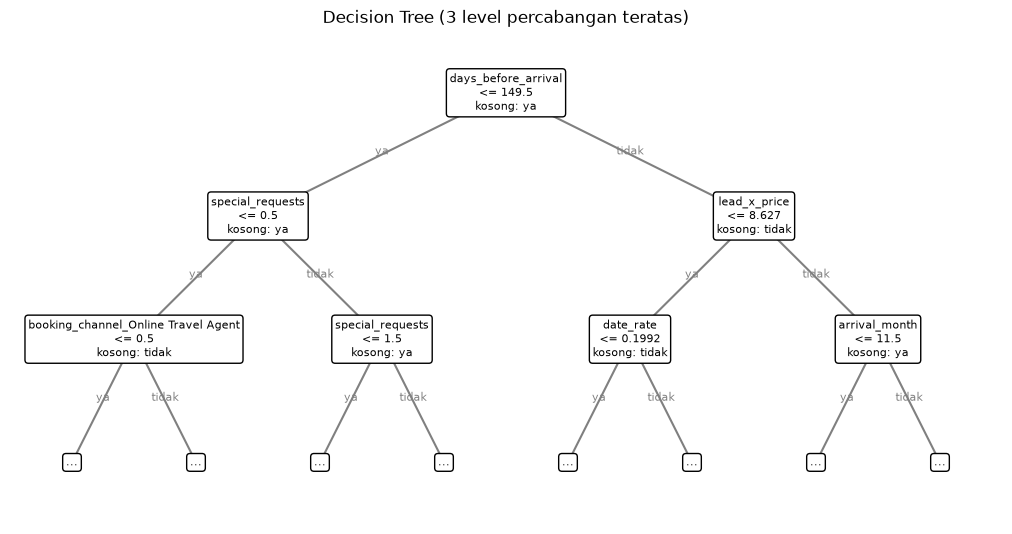

In [32]:
dtl_fitted = fit(tuned_models["dtl"], X_trains["dtl"], y_train, METHOD)
fig = plot_tree(dtl_fitted, list(X_trains["dtl"].columns), top_n=3, path=Settings.OUTPUT_DIR / "dtl_tree.png")
fig

### Bonus Bayesian Network

Eksperimen membandingkan Naive Bayes, TAN, dan KDB. Graf TAN berikut memperlihatkan dependensi antarfitur yang dipelajari model.

In [33]:
bn_variants = {
    "bn_nb": BayesNetwork(n_bins=5),
    "bn_tan": BayesNetwork(n_bins=5, tree=True),
    "bn_kdb": BayesNetwork(n_bins=5, k=10),
}
compare(holdout(bn_variants, X_train, y_train, X_val, y_val, METHOD), kfold(bn_variants, X_train, y_train, METHOD))

,holdout,kfold_mean,kfold_std
bn_kdb,0.811249,0.812400,0.002917
bn_tan,0.764475,0.759517,0.003993
bn_nb,0.705022,0.709303,0.006095


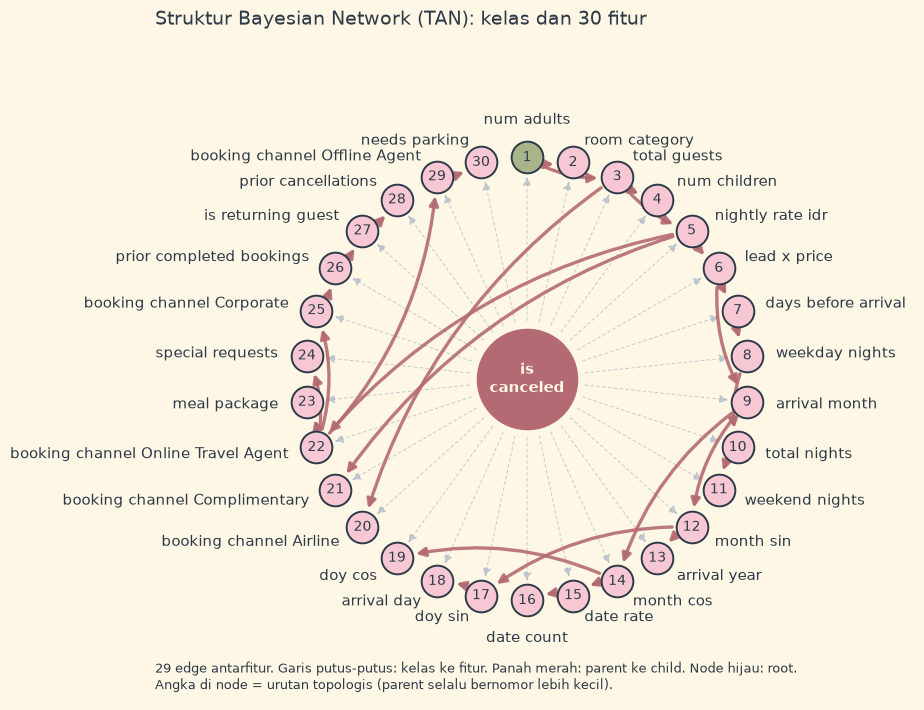

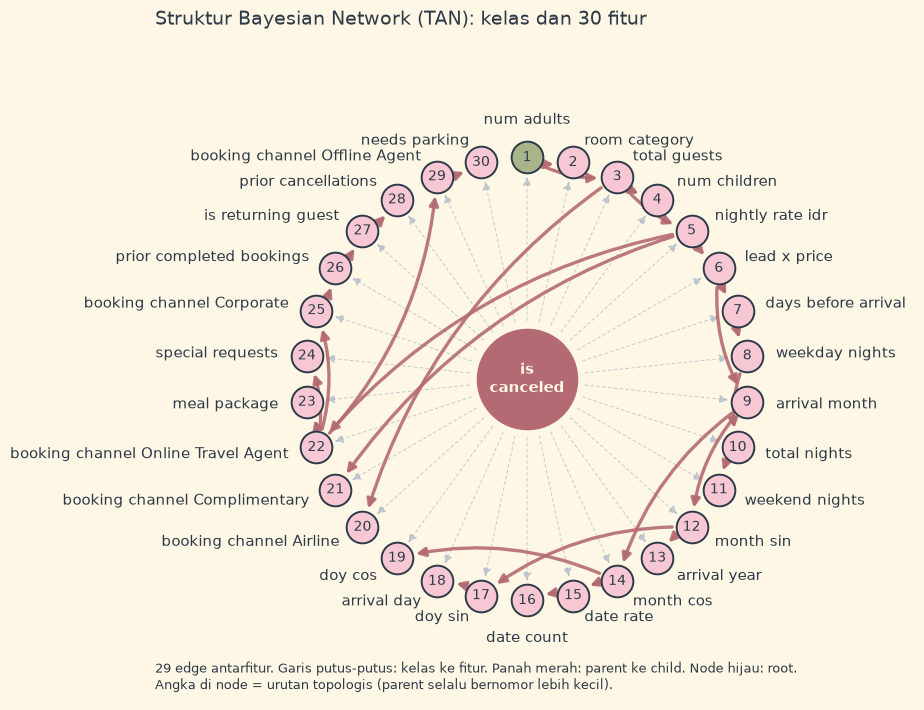

In [34]:
bn_tan = fit(BayesNetwork(n_bins=5, tree=True), X_train, y_train, METHOD)
fig = plot_bayes_graph(bn_tan, list(X_train.columns), class_name=Settings.TARGET)
fig.savefig(Settings.OUTPUT_DIR / "bayes_graph.png", dpi=160, bbox_inches="tight")
fig

### Bonus Optimisasi Logistic Regression

Model `lr` pada bagian Modeling and Validation tetap memakai implementasi from-scratch di `src/models/logistic_regression.py`. Eksperimen ini membandingkan batch GD, mini-batch SGD, dan L-BFGS from scratch dengan fitur c010 yang sama. Evaluasi memakai stratified holdout 20% (seed 42), regularisasi L2 0.1, dan threshold 0.42. Cell berikut menampilkan macro F1, accuracy, log-loss, dan status solver, serta menghasilkan tiga CSV prediksi dan `lr_c010_solver_comparison.csv`.

> Referensi L-BFGS: Liu dan Nocedal (1989), *Mathematical Programming* 45, 503-528, [PDF mirror Florida State University](https://people.sc.fsu.edu/~inavon/5420a/liu89limited.pdf). Saratchandran et al. (2023), arXiv:2305.08552, section 3.2, [HTML](https://arxiv.org/html/2305.08552).
> Line search Armijo dan Strong Wolfe: [Wolfram Language Documentation](https://reference.wolframcloud.com/language/tutorial/UnconstrainedOptimizationStepControl.html). Rujukan asli Armijo (1966), *Pacific Journal of Mathematics* 16(1), 1-3, [PDF langsung](https://msp.org/pjm/1966/16-1/pjm-v16-n1-p01-p.pdf).
> Gradient descent dan variannya: [GeeksforGeeks](https://www.geeksforgeeks.org/machine-learning/gradient-descent-algorithm-and-its-variants/) dan [IBM Think](https://www.ibm.com/think/topics/gradient-descent).

batch_gradient_descent: macro-F1=0.84197, accuracy=0.86064, log-loss=0.31151, iterations=1500, converged=False
mini_batch_sgd: macro-F1=0.84237, accuracy=0.86082, log-loss=0.31146, iterations=120, converged=False
lbfgs_scratch: macro-F1=0.84976, accuracy=0.86831, log-loss=0.29104, iterations=853, converged=True
6844 predictions saved to /Users/bryanpratama/Documents/Tubes/AI/IF3170_G08_Teazzi/output/lr_c010_batch_gd.csv
6844 predictions saved to /Users/bryanpratama/Documents/Tubes/AI/IF3170_G08_Teazzi/output/lr_c010_minibatch_sgd.csv
6844 predictions saved to /Users/bryanpratama/Documents/Tubes/AI/IF3170_G08_Teazzi/output/lr_calendar_density_c010_lbfgs_scratch.csv
Validation comparison saved to /Users/bryanpratama/Documents/Tubes/AI/IF3170_G08_Teazzi/output/lr_c010_solver_comparison.csv


,model,validation_macro_f1,validation_accuracy,validation_log_loss,iterations,converged
2,lbfgs_scratch,0.849757,0.868311,0.291044,853,True
1,mini_batch_sgd,0.842375,0.860822,0.311464,120,False
0,batch_gradient_descent,0.841966,0.860639,0.311511,1500,False


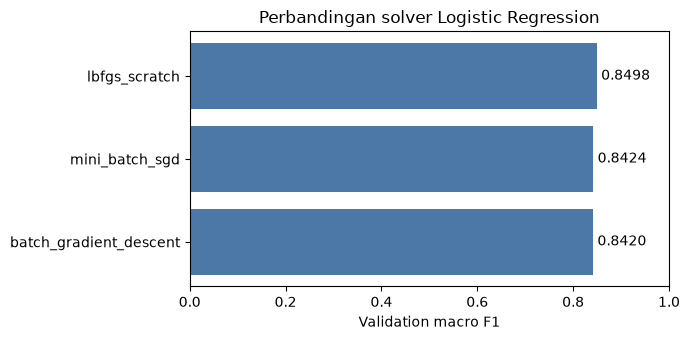

In [35]:
lr_solver_results, lr_solver_outputs = run_three_solver_submissions()
solver_metrics = lr_solver_results[["model", "validation_macro_f1", "validation_accuracy", "validation_log_loss", "iterations", "converged"]]
display(solver_metrics)

solver_plot = lr_solver_results.sort_values("validation_macro_f1")
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(solver_plot["model"], solver_plot["validation_macro_f1"], color="#4C78A8")
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set(title="Perbandingan solver Logistic Regression", xlabel="Validation macro F1", xlim=(0, 1), ylabel="")
plt.tight_layout()
plt.show()

---

# Comparison with scikit-learn <a name="8"></a>

---

Setiap pasangan baseline memakai split yang sama dengan model dari nol. Naive Bayes dari nol mendiskretisasi fitur, sedangkan baseline memakai GaussianNB. Baseline KNN juga memakai seleksi fitur DTL.

In [36]:
ranker = DTL(criterion="entropy", max_depth=10, min_samples_split=50)

sk_models = {
    "sk_knn": Pipeline(KNeighborsClassifier(5, metric="manhattan"), select=12, ranker=ranker),
    "sk_lr": SkLogisticRegression(max_iter=3000),
    "sk_svm": SVC(kernel="rbf", C=2, gamma=0.025),
    "sk_dtl": DecisionTreeClassifier(criterion="gini", ccp_alpha=3e-4, random_state=Settings.SEED),
    "sk_nb": GaussianNB(),
}

,From scratch,scikit-learn
knn,0.8423,0.8197
dtl,0.8277,0.8273
lr,0.7597,0.8017
svm,0.8688,0.8688
bn,0.7050,0.3797


,holdout,kfold_mean,kfold_std
svm,0.8688,0.8645,0.0037
sk_svm,0.8688,0.8645,0.0038
knn,0.8423,0.8382,0.0051
dtl,0.8277,0.8223,0.0070
sk_dtl,0.8273,0.8221,0.0071
sk_knn,0.8197,0.8172,0.0057
bn_kdb,0.8112,0.8124,0.0029
sk_lr,0.8017,0.7914,0.0034
bn,0.7050,0.7093,0.0061
lr,0.7597,0.6861,0.0397


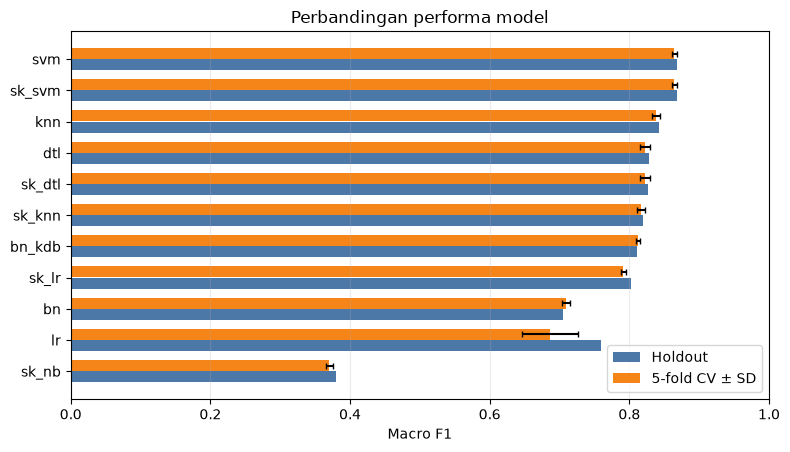

In [37]:
sk_holdout = holdout(sk_models, X_trains, y_train, X_vals, y_val, METHOD)
sk_cv = kfold(sk_models, X_trains, y_train, METHOD)
comparison_table = compare(pd.concat([scratch_holdout, sk_holdout]), pd.concat([scratch_cv, sk_cv]))

pairs = {"knn": "sk_knn", "dtl": "sk_dtl", "lr": "sk_lr", "svm": "sk_svm", "bn": "sk_nb"}
paired_holdout = pd.DataFrame(
    {
        "From scratch": [comparison_table.at[name, "holdout"] for name in pairs],
        "scikit-learn": [comparison_table.at[name, "holdout"] for name in pairs.values()],
    },
    index=list(pairs),
)
display(paired_holdout.round(4))
display(comparison_table.round(4))

plot_table = comparison_table.dropna(subset=["holdout", "kfold_mean"]).sort_values("kfold_mean")
positions = np.arange(len(plot_table))
fig, ax = plt.subplots(figsize=(8, max(4, 0.42 * len(plot_table))))
ax.barh(positions - 0.18, plot_table["holdout"], height=0.35, label="Holdout", color="#4C78A8")
ax.barh(
    positions + 0.18,
    plot_table["kfold_mean"],
    xerr=plot_table["kfold_std"],
    height=0.35,
    capsize=2,
    label="5-fold CV ± SD",
    color="#F58518",
)
ax.set(yticks=positions, yticklabels=plot_table.index, xlabel="Macro F1", xlim=(0, 1), title="Perbandingan performa model")
ax.legend()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

---

# Saving and Loading Models <a name="9"></a>

---

Lima model dasar yang dilatih pada split train disimpan di `output/validation_models/`. Setelah dimuat ulang, model memprediksi sampel validation dengan preprocessing yang sama. Bagian submission menyimpan model final dan preprocessornya secara terpisah.

In [38]:
model_dir = Settings.OUTPUT_DIR / "validation_models"
model_dir.mkdir(exist_ok=True)

reload_matches = {}
for name in ("knn", "dtl", "lr", "svm", "bn"):
    fitted = fitted_models[name]
    model_path = model_dir / f"{name}.pkl"
    fitted.save(model_path)
    restored = BaseModel.load(model_path)
    sample = X_vals[name].head()
    reload_matches[name] = np.array_equal(
        fitted.predict(model_input(fitted, sample)),
        restored.predict(model_input(restored, sample)),
    )

pd.Series(reload_matches, name="Prediksi sebelum dan sesudah load sama")

knn    True
dtl    True
lr     True
svm    True
bn     True
Name: Prediksi sebelum dan sesudah load sama, dtype: bool

---

# Kaggle Submission <a name="10"></a>

---

## KNN Robust

KNN dari nol dan robust preprocessor dilatih ulang pada seluruh `train.csv` dengan `knn_config`. `test.csv` hanya ditransformasi dan diprediksi. File `knn_robust_*.csv` berisi satu label per ID, dengan kolom `id,is_canceled`.

In [39]:
X_full = train.drop(columns=[Settings.ID, Settings.TARGET])
y_full = train[Settings.TARGET]
prep_final = deepcopy(preps["knn"])
X_full_prepared = prep_final.fit_transform(X_full, y_full)
X_test_prepared = prep_final.transform(test.drop(columns=[Settings.ID]))

submit(
    KNN(**knn_config),
    "knn_robust",
    X_full_prepared,
    y_full,
    X_test_prepared,
    test[Settings.ID],
    METHOD,
    preprocessor=prep_final,
)

Preprocessor saved to /Users/bryanpratama/Documents/Tubes/AI/IF3170_G08_Teazzi/output/knn_robust_20261124-105937_preprocessor.pkl
6844 rows written to /Users/bryanpratama/Documents/Tubes/AI/IF3170_G08_Teazzi/output/knn_robust_20261124-105937.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


## SVM dengan Price Target Encoding

Jalur ini mereproduksi submission SVM dari commit `7b569d5`. SVM RBF memakai `C=2` dan `gamma=0.025`. Preprocessing mengikuti resep saat itu, termasuk standardisasi fitur biner dan rata-rata label data fit sebagai prior smoothing. Threshold dipilih dengan 5-fold out-of-fold macro F1 pada `train.csv`, dengan preprocessing di-fit ulang pada bagian latih setiap fold.

Model final dilatih ulang pada seluruh `train.csv`. Unggah `svm_price_te_*.csv` yang dicetak oleh cell ini untuk submission SVM.

In [ ]:
svm_train_raw = train.drop(columns=[Settings.ID, Settings.TARGET])
svm_test_raw = test.drop(columns=[Settings.ID])
svm_y = train[Settings.TARGET]

svm_prep = Preprocessor(**SVM_PREP_OPTIONS, scale_binary=True, use_fold_priors=False)
svm_final = with_threshold(SVM(kernel="rbf", C=2, gamma=0.025), svm_train_raw, svm_y, prep=svm_prep)
print(f"Threshold SVM: {svm_final.threshold:.12f}")

svm_train_prepared = svm_prep.fit_transform(svm_train_raw, svm_y)
svm_test_prepared = svm_prep.transform(svm_test_raw)

submit(
    svm_final,
    "svm_price_te",
    svm_train_prepared,
    svm_y,
    svm_test_prepared,
    test[Settings.ID],
    preprocessor=svm_prep,
)

---

# Error Analysis <a name="11"></a>

---

## Confusion Matrix dan Classification Report

Confusion matrix menampilkan tiga model teratas dari ranking CV setelah tuning. Baris adalah label sebenarnya dan kolom adalah label prediksi. Classification report merangkum precision, recall, dan F1 tiap kelas pada holdout untuk semua model hasil tuning.

In [40]:
if ranking.empty:
    ranking = compare(holdout(sk_models, X_trains, y_train, X_vals, y_val, METHOD), kfold(sk_models, X_trains, y_train, METHOD))
    tuned_models = {**tuned_models, **sk_models}

best_name = ranking.index[0]
best_model = tuned_models[best_name]
best_name, best_model

('svm', <models.svm.SVM at 0x11a42d390>)

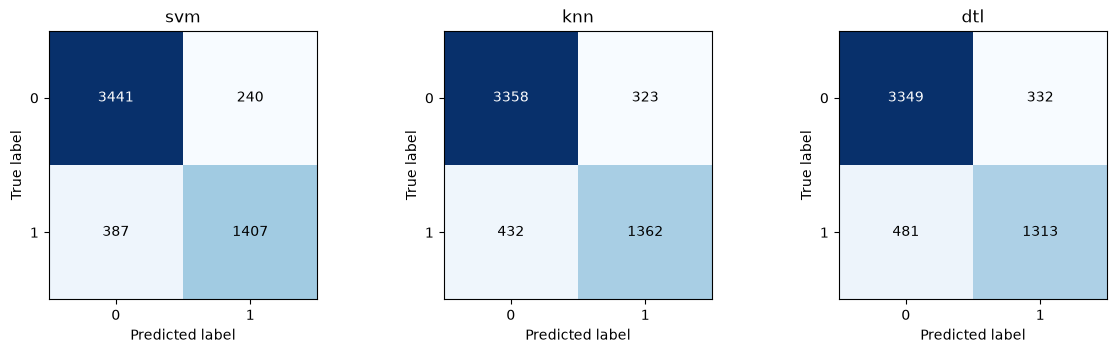

In [41]:
confusion_models = {name: tuned_models[name] for name in ranking.index[:3]}
confusion(confusion_models, X_trains, y_train, X_vals, y_val, METHOD)

In [46]:
report(tuned_models, X_trains, y_train, X_vals, y_val, METHOD)

precision    recall  f1-score  support
knn    0           0.886016  0.912252  0.898943   3681.0
       1           0.808309  0.759197  0.782984   1794.0
       macro avg   0.847162  0.835725  0.840963   5475.0
       accuracy         NaN       NaN  0.862100   5475.0
lr     0           0.828335  0.870416  0.848854   3681.0
       1           0.703174  0.629877  0.664510   1794.0
       macro avg   0.765754  0.750147  0.756682   5475.0
       accuracy         NaN       NaN  0.791598   5475.0
svm    0           0.898903  0.934800  0.916500   3681.0
       1           0.854281  0.784281  0.817786   1794.0
       macro avg   0.876592  0.859541  0.867143   5475.0
       accuracy         NaN       NaN  0.885479   5475.0
dtl    0           0.874413  0.909807  0.891759   3681.0
       1           0.798176  0.731884  0.763594   1794.0
       macro avg   0.836294  0.820846  0.827676   5475.0
       accuracy         NaN       NaN  0.851507   5475.0
bn     0           0.832982  0.751970  0.790405   3681.0
       1           0.575743  0.690635  0.627978   1794.0
       macro avg   0.704363  0.721303  0.709192   5475.0
       accuracy         NaN       NaN  0.731872   5475.0
bn_kdb 0           0.857288  0.913882  0.884681   3681.0
       1           0.795616  0.687848  0.737818   1794.0
       macro avg   0.826452  0.800865  0.811249   5475.0
       accuracy         NaN       NaN  0.839817   5475.0

## Contoh Kesalahan Prediksi

*False positive* memprediksi reservasi aktif sebagai batal, yang berisiko menyebabkan overbooking. *False negative* melewatkan pembatalan, sehingga hotel bisa kehilangan kesempatan menjual kamar kembali.

In [43]:
wrong_rows = misclassified(best_model, train, X_trains[best_name], y_train, X_vals[best_name], y_val, METHOD)
print(f"{len(wrong_rows)} dari {len(X_val)} baris salah")
error_counts = wrong_rows["predicted"].map({1: "False positive", 0: "False negative"}).value_counts()
display(error_counts.reindex(["False positive", "False negative"], fill_value=0))
wrong_rows[[Settings.ID, "days_before_arrival", "booking_channel", Settings.TARGET, "predicted"]].head()

627 dari 5475 baris salah


predicted
False positive    240
False negative    387
Name: count, dtype: int64

,id,days_before_arrival,booking_channel,is_canceled,predicted
139,50bd8e8e,125.0,Online Travel Agent,1,0
308,7c9b4fa0,66.0,Online Travel Agent,1,0
322,c55f977e,67.0,Online Travel Agent,1,0
346,bf7a401e,13.0,Online Travel Agent,0,1
358,b26fe050,14.0,Online Travel Agent,1,0


## Feature Importance

Grafik mengurutkan fitur menurut kontribusinya terhadap penurunan impurity pada baseline CART.

,importance
days_before_arrival,0.331707
lead_x_price,0.164303
booking_channel_Online Travel Agent,0.130229
special_requests,0.112649
date_rate,0.085729
doy_cos,0.025390
doy_sin,0.020533
nightly_rate_idr,0.019517
weekend_nights,0.015308
date_count,0.014795


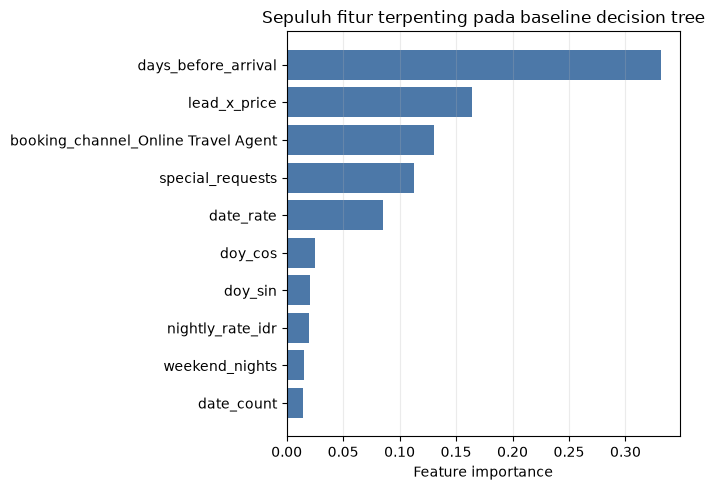

In [44]:
dtl_importance = importance(sk_models["sk_dtl"], X_trains["sk_dtl"], y_train).head(10)
display(dtl_importance.rename("importance").to_frame())

plot_importance = dtl_importance.sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(plot_importance.index, plot_importance.values, color="#4C78A8")
ax.set(title="Sepuluh fitur terpenting pada baseline decision tree", xlabel="Feature importance", ylabel="")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## Cost-Sensitive Classification

Bandingkan konfigurasi Bayesian Network dengan dan tanpa biaya false positive dua kali lebih besar dari false negative. Tabel menampilkan perubahan kedua jenis kesalahan, biaya total, dan macro F1.

In [45]:
cost_variants = {
    "nb": BayesNetwork(n_bins=5),
    "nb + biaya": BayesNetwork(n_bins=5, cost_fp=2),
    "tan": BayesNetwork(n_bins=5, tree=True),
    "tan + biaya": BayesNetwork(n_bins=5, tree=True, cost_fp=2),
    "kdb": BayesNetwork(n_bins=5, k=10),
    "kdb + biaya": BayesNetwork(n_bins=5, k=10, cost_fp=2),
}

rows = {}
for name, model in cost_variants.items():
    predicted, actual = fit_predict(model, X_train, y_train, X_val, METHOD), y_val.values
    fp, fn = ((predicted == 1) & (actual == 0)).sum(), ((predicted == 0) & (actual == 1)).sum()
    rows[name] = {"FP": fp, "FN": fn, "biaya (2 FP + FN)": 2 * fp + fn, "macro F1": macro_f1(actual, predicted)}
pd.DataFrame(rows).T.astype({"FP": int, "FN": int, "biaya (2 FP + FN)": int})

,FP,FN,biaya (2 FP + FN),macro F1
nb,963,537,2463,0.705022
nb + biaya,732,650,2114,0.716799
tan,511,609,1631,0.764475
tan + biaya,273,791,1337,0.759197
kdb,317,560,1194,0.811249
kdb + biaya,265,601,1131,0.810603
